In [ ]:
# ================================================================
# CONTEXTUAL BANDIT-BASED ADAPTIVE SYNCHRONIZATION AND RETRAINING
# OF UAV NETWORK DIGITAL TWIN
#
# CURRENT IMPLEMENTED STAGE:
# Multi-UAV Synchronization using Random Forest Regression
# ================================================================

# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


# ================================================================
# 2. INITIALIZE UAV NETWORK
# ================================================================

num_uavs = 3

# Initial positions of the 3 UAVs
start_positions = np.array([
    [0, 0],
    [0, 10],
    [10, 0]
], dtype=float)

# Common target
target = np.array([20, 20], dtype=float)

# Initial speeds of UAVs
initial_speeds = np.array([
    0.8,
    0.5,
    1.0
], dtype=float)

print("=" * 65)
print("MULTI-UAV SYNCHRONIZATION PROJECT")
print("=" * 65)

print("\nINITIAL UAV CONFIGURATION")
print("-" * 65)

print("Number of UAVs:", num_uavs)

for i in range(num_uavs):
    print(
        f"UAV {i+1}: "
        f"Position = {start_positions[i]}, "
        f"Initial Speed = {initial_speeds[i]:.2f} m/s"
    )

print(f"Common Target: {target}")


# ================================================================
# 3. CALCULATE INITIAL DISTANCES
# ================================================================

initial_distances = np.linalg.norm(
    target - start_positions,
    axis=1
)

print("\nINITIAL DISTANCES")
print("-" * 65)

for i in range(num_uavs):
    print(
        f"UAV {i+1}: "
        f"{initial_distances[i]:.2f} meters"
    )


# ================================================================
# 4. CALCULATE INITIAL ARRIVAL TIMES
# ================================================================

initial_arrival_times = (
    initial_distances / initial_speeds
)

# The slowest UAV determines the common arrival time
common_time = np.max(initial_arrival_times)

print("\nINITIAL ARRIVAL TIMES")
print("-" * 65)

for i in range(num_uavs):
    print(
        f"UAV {i+1}: "
        f"{initial_arrival_times[i]:.2f} seconds"
    )

print(
    f"\nCommon Arrival Time: "
    f"{common_time:.2f} seconds"
)


# ================================================================
# 5. INITIAL SYNCHRONIZATION ERROR
# ================================================================

initial_sync_error = (
    np.max(initial_arrival_times)
    - np.min(initial_arrival_times)
)

print(
    f"Initial Synchronization Error: "
    f"{initial_sync_error:.2f} seconds"
)


# ================================================================
# 6. GENERATE SYNTHETIC DATASET
# ================================================================
#
# 1000 simulated UAV scenarios
#
# Features:
# 1. Distance
# 2. Current Speed
# 3. Arrival Time
# 4. Common Arrival Time
# 5. Synchronization Error
#
# Target:
# Required Speed
# ================================================================

np.random.seed(42)

samples = 1000

# Random distance between 5 and 50 meters
distance = np.random.uniform(
    5,
    50,
    samples
)

# Random current speed between 0.3 and 1.5 m/s
current_speed = np.random.uniform(
    0.3,
    1.5,
    samples
)

# Calculate arrival time
arrival_time = (
    distance / current_speed
)

# Generate common arrival time
common_time_data = np.random.uniform(
    10,
    60,
    samples
)

# Calculate synchronization error
sync_error = np.abs(
    arrival_time - common_time_data
)

# Calculate required speed
required_speed = (
    distance / common_time_data
)

# Limit speed between 0.2 and 2.0 m/s
required_speed = np.clip(
    required_speed,
    0.2,
    2.0
)

# Create input feature matrix
X = np.column_stack([
    distance,
    current_speed,
    arrival_time,
    common_time_data,
    sync_error
])

# Target output
y = required_speed

print("\nDATASET INFORMATION")
print("-" * 65)

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("Total Scenarios:", samples)

print("\nInput Features:")
print("1. Distance")
print("2. Current Speed")
print("3. Arrival Time")
print("4. Common Arrival Time")
print("5. Synchronization Error")

print("\nOutput:")
print("Required Speed")


# ================================================================
# 7. SPLIT DATA INTO TRAINING AND TESTING
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nDATA SPLIT")
print("-" * 65)

print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))


# ================================================================
# 8. TRAIN RANDOM FOREST REGRESSION MODEL
# ================================================================

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(
    X_train,
    y_train
)


# ================================================================
# 9. MODEL PREDICTION AND EVALUATION
# ================================================================

predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    predictions
)

r2 = r2_score(
    y_test,
    predictions
)

print("\nRANDOM FOREST MODEL RESULTS")
print("-" * 65)

print("Algorithm: Random Forest Regression")
print("Number of Trees:", 100)

print(f"MAE      : {mae:.4f}")
print(f"R2 Score : {r2:.4f}")


# ================================================================
# 10. SINGLE UAV TEST
# ================================================================

test_distance = 30.0
test_current_speed = 0.7

test_arrival_time = (
    test_distance /
    test_current_speed
)

test_common_time = 40.0

test_sync_error = abs(
    test_arrival_time -
    test_common_time
)

test_input = np.array([[
    test_distance,
    test_current_speed,
    test_arrival_time,
    test_common_time,
    test_sync_error
]])

single_uav_prediction = model.predict(
    test_input
)[0]

print("\nSINGLE UAV ML TEST")
print("-" * 65)

print(f"Distance              : {test_distance:.2f} m")
print(f"Current Speed         : {test_current_speed:.2f} m/s")
print(f"Arrival Time          : {test_arrival_time:.2f} s")
print(f"Common Time           : {test_common_time:.2f} s")
print(f"Synchronization Error : {test_sync_error:.2f} s")
print(
    f"Predicted Required Speed : "
    f"{single_uav_prediction:.3f} m/s"
)


# ================================================================
# 11. APPLY ML MODEL TO 3 UAVs
# ================================================================

# Synchronization error for each UAV
uav_sync_errors = np.abs(
    initial_arrival_times -
    common_time
)

# Create input data for 3 UAVs
ml_inputs = np.column_stack([
    initial_distances,
    initial_speeds,
    initial_arrival_times,
    np.full(num_uavs, common_time),
    uav_sync_errors
])

# Predict required speed
predicted_speeds = model.predict(
    ml_inputs
)

# Calculate final arrival times
final_arrival_times = (
    initial_distances /
    predicted_speeds
)

# Final synchronization error
final_sync_error = (
    np.max(final_arrival_times)
    -
    np.min(final_arrival_times)
)


# ================================================================
# 12. DISPLAY FINAL UAV SYNCHRONIZATION RESULTS
# ================================================================

print("\n")
print("=" * 65)
print("ML-BASED MULTI-UAV SYNCHRONIZATION RESULTS")
print("=" * 65)

for i in range(num_uavs):

    print(
        f"\nUAV {i+1}"
    )

    print(
        f"Distance              : "
        f"{initial_distances[i]:.2f} m"
    )

    print(
        f"Initial Speed         : "
        f"{initial_speeds[i]:.3f} m/s"
    )

    print(
        f"Initial Arrival Time  : "
        f"{initial_arrival_times[i]:.2f} s"
    )

    print(
        f"ML Predicted Speed    : "
        f"{predicted_speeds[i]:.3f} m/s"
    )

    print(
        f"Final Arrival Time    : "
        f"{final_arrival_times[i]:.2f} s"
    )

print("\n" + "-" * 65)

print(
    f"Final Synchronization Error: "
    f"{final_sync_error:.3f} seconds"
)


# ================================================================
# 13. BEFORE vs AFTER SYNCHRONIZATION PLOT
# ================================================================

uav_labels = [
    "UAV 1",
    "UAV 2",
    "UAV 3"
]

x = np.arange(num_uavs)

width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    initial_arrival_times,
    width,
    label="Before ML"
)

plt.bar(
    x + width / 2,
    final_arrival_times,
    width,
    label="After ML"
)

plt.xlabel("UAV")
plt.ylabel("Arrival Time (seconds)")

plt.title(
    "UAV Arrival Time Before and After ML Synchronization"
)

plt.xticks(
    x,
    uav_labels
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ================================================================
# 14. UAV MOVEMENT SIMULATION
# ================================================================

# Copy starting positions
sim_positions = start_positions.copy()

# Store UAV paths
paths = [
    [] for _ in range(num_uavs)
]

# Simulation parameters
dt = 0.1
simulation_steps = 500

# Run movement simulation
for step in range(simulation_steps):

    for i in range(num_uavs):

        # Direction from UAV to target
        direction = (
            target -
            sim_positions[i]
        )

        # Remaining distance
        remaining_distance = np.linalg.norm(
            direction
        )

        # Move UAV if it has not reached target
        if remaining_distance > 0.01:

            # Normalize direction
            direction = (
                direction /
                remaining_distance
            )

            # Movement distance
            movement_distance = (
                predicted_speeds[i] *
                dt
            )

            # Avoid moving beyond target
            movement_distance = min(
                movement_distance,
                remaining_distance
            )

            # Update UAV position
            sim_positions[i] += (
                direction *
                movement_distance
            )

        # Store position
        paths[i].append(
            sim_positions[i].copy()
        )


# ================================================================
# 15. PLOT UAV MOVEMENT PATHS
# ================================================================

plt.figure(figsize=(8, 6))

for i in range(num_uavs):

    path = np.array(
        paths[i]
    )

    plt.plot(
        path[:, 0],
        path[:, 1],
        label=f"UAV {i+1}"
    )

# Plot starting positions
plt.scatter(
    start_positions[:, 0],
    start_positions[:, 1],
    marker="o",
    s=80,
    label="Starting Positions"
)

# Plot target
plt.scatter(
    target[0],
    target[1],
    marker="*",
    s=250,
    label="Common Target"
)

plt.xlabel("X Position")

plt.ylabel("Y Position")

plt.title(
    "ML-Based Multi-UAV Synchronized Movement"
)

plt.legend()

plt.grid(True)

plt.axis("equal")

plt.tight_layout()

plt.show()


# ================================================================
# 16. CREATE UAV ANIMATION
# ================================================================

# Convert paths into NumPy arrays
path_arrays = [
    np.array(path)
    for path in paths
]

# Number of animation frames
frames = len(path_arrays[0])

fig, ax = plt.subplots(
    figsize=(8, 6)
)

# Set plot limits
ax.set_xlim(
    -2,
    max(target[0] + 2, 22)
)

ax.set_ylim(
    -2,
    max(target[1] + 2, 22)
)

ax.set_xlabel("X Position")

ax.set_ylabel("Y Position")

ax.set_title(
    "Animated Multi-UAV Synchronization"
)

ax.grid(True)

# Plot target
ax.scatter(
    target[0],
    target[1],
    marker="*",
    s=250,
    label="Target"
)

# UAV markers
uav_markers = []

# UAV path lines
uav_lines = []

for i in range(num_uavs):

    marker, = ax.plot(
        [],
        [],
        "o",
        markersize=8,
        label=f"UAV {i+1}"
    )

    line, = ax.plot(
        [],
        [],
        "--",
        alpha=0.5
    )

    uav_markers.append(marker)

    uav_lines.append(line)


# Time text
time_text = ax.text(
    0.02,
    0.95,
    "",
    transform=ax.transAxes
)


# ------------------------------------------------
# Animation initialization
# ------------------------------------------------

def init():

    for marker, line in zip(
        uav_markers,
        uav_lines
    ):

        marker.set_data(
            [],
            []
        )

        line.set_data(
            [],
            []
        )

    time_text.set_text("")

    return (
        uav_markers +
        uav_lines +
        [time_text]
    )


# ------------------------------------------------
# Animation update
# ------------------------------------------------

def update(frame):

    current_time = frame * dt

    for i in range(num_uavs):

        x_pos = path_arrays[i][
            :frame + 1,
            0
        ]

        y_pos = path_arrays[i][
            :frame + 1,
            1
        ]

        # Current UAV position
        uav_markers[i].set_data(
            [x_pos[-1]],
            [y_pos[-1]]
        )

        # UAV path
        uav_lines[i].set_data(
            x_pos,
            y_pos
        )

    time_text.set_text(
        f"Simulation Time: "
        f"{current_time:.1f} s"
    )

    return (
        uav_markers +
        uav_lines +
        [time_text]
    )


# Create animation
animation = FuncAnimation(
    fig,
    update,
    frames=frames,
    init_func=init,
    interval=30,
    blit=True,
    repeat=False
)

plt.close(fig)

display(
    HTML(
        animation.to_jshtml()
    )
)


# ================================================================
# 17. FINAL PROJECT SUMMARY
# ================================================================

print("\n")
print("=" * 65)
print("FINAL PROJECT SUMMARY")
print("=" * 65)

print("\nML MODEL")
print("-" * 65)
print("Algorithm              : Random Forest Regression")
print("Training Samples       : 800")
print("Testing Samples        : 200")
print("Total Dataset Samples  : 1000")
print(f"MAE                    : {mae:.4f}")
print(f"R2 Score               : {r2:.4f}")

print("\nUAV SYNCHRONIZATION")
print("-" * 65)

for i in range(num_uavs):

    print(
        f"UAV {i+1}: "
        f"Initial Speed = "
        f"{initial_speeds[i]:.3f} m/s, "
        f"ML Speed = "
        f"{predicted_speeds[i]:.3f} m/s, "
        f"Arrival Time = "
        f"{final_arrival_times[i]:.2f} s"
    )

print(
    f"\nInitial Synchronization Error : "
    f"{initial_sync_error:.2f} seconds"
)

print(
    f"Final Synchronization Error   : "
    f"{final_sync_error:.3f} seconds"
)

print("\nCurrent Implementation:")
print("✓ Multi-UAV simulation")
print("✓ Distance calculation")
print("✓ Arrival-time calculation")
print("✓ Synchronization-error calculation")
print("✓ Synthetic dataset generation")
print("✓ Random Forest Regression")
print("✓ Required-speed prediction")
print("✓ Multi-UAV ML integration")
print("✓ UAV movement simulation")
print("✓ Path visualization")
print("✓ UAV animation")

print("\nFuture Work:")
print("→ Traffic conditions")
print("→ Network load")
print("→ Delay and operational cost")
print("→ Contextual Bandit")
print("→ MOVE / WAIT / RETAIN / RETRAIN decisions")
print("→ UAV Network Digital Twin")
print("→ Adaptive model retraining")
print("→ Realistic UAV simulator / real-world data")

print("=" * 65)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:

# ================================================================
# CONTEXTUAL BANDIT-BASED ADAPTIVE SYNCHRONIZATION AND RETRAINING
# OF UAV NETWORK DIGITAL TWIN
#
# Complete standalone prototype
# Python + NumPy + Matplotlib + Scikit-learn
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

np.random.seed(42)

# ================================================================
# 1. UAV CONFIGURATION
# ================================================================

NUM_UAVS = 3

START_POSITIONS = np.array([
    [0.0, 0.0],
    [0.0, 10.0],
    [10.0, 0.0]
])

TARGET = np.array([20.0, 20.0])

INITIAL_SPEEDS = np.array([0.8, 0.5, 1.0])

MIN_SPEED = 0.2
MAX_SPEED = 2.0

print("=" * 65)
print("UAV NETWORK SYNCHRONIZATION PROJECT")
print("=" * 65)

print("\nInitial UAV Configuration")

for i in range(NUM_UAVS):
    print(
        f"UAV {i+1}: Position={START_POSITIONS[i]}, "
        f"Speed={INITIAL_SPEEDS[i]:.2f} m/s"
    )

print("Common Target:", TARGET)


# ================================================================
# 2. CALCULATE DISTANCE, ARRIVAL TIME AND SYNC ERROR
# ================================================================

def get_uav_metrics(positions, speeds, target):
    distances = np.linalg.norm(target - positions, axis=1)
    arrival_times = distances / np.maximum(speeds, 1e-6)
    common_time = np.max(arrival_times)
    sync_error = np.max(arrival_times) - np.min(arrival_times)
    individual_errors = np.abs(arrival_times - common_time)

    return distances, arrival_times, common_time, sync_error, individual_errors


distances, initial_times, common_time, initial_sync_error, individual_errors = (
    get_uav_metrics(START_POSITIONS, INITIAL_SPEEDS, TARGET)
)

print("\nInitial Arrival Times")

for i in range(NUM_UAVS):
    print(
        f"UAV {i+1}: Distance={distances[i]:.2f} m, "
        f"Arrival={initial_times[i]:.2f} s"
    )

print(f"Initial synchronization error: {initial_sync_error:.3f} s")


# ================================================================
# 3. CREATE SYNTHETIC UAV DATASET
# ================================================================

SAMPLES = 1000

distance_data = np.random.uniform(5, 50, SAMPLES)
speed_data = np.random.uniform(0.3, 1.5, SAMPLES)
arrival_data = distance_data / speed_data
common_data = np.random.uniform(10, 60, SAMPLES)
error_data = np.abs(arrival_data - common_data)

# Mathematical target for supervised learning
required_speed_data = np.clip(
    distance_data / common_data,
    MIN_SPEED,
    MAX_SPEED
)

X = np.column_stack([
    distance_data,
    speed_data,
    arrival_data,
    common_data,
    error_data
])

y = required_speed_data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("\nDataset Information")
print("Total scenarios:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", X.shape[1])


# ================================================================
# 4. TRAIN RANDOM FOREST REGRESSION
# ================================================================

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

test_predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
r2 = r2_score(y_test, test_predictions)

print("\nRandom Forest Evaluation")
print("Algorithm: Random Forest Regression")
print(f"MAE: {mae:.4f}")
print(f"R2 score: {r2:.4f}")


# ================================================================
# 5. PREDICT SPEEDS FOR THREE UAVS
# ================================================================

ml_inputs = np.column_stack([
    distances,
    INITIAL_SPEEDS,
    initial_times,
    np.full(NUM_UAVS, common_time),
    individual_errors
])

predicted_speeds = np.clip(
    model.predict(ml_inputs),
    MIN_SPEED,
    MAX_SPEED
)

predicted_times = distances / predicted_speeds

final_sync_error = (
    np.max(predicted_times) - np.min(predicted_times)
)

print("\nML-Based Synchronization Results")
print("-" * 65)

for i in range(NUM_UAVS):
    print(
        f"UAV {i+1}: Initial speed={INITIAL_SPEEDS[i]:.3f} m/s, "
        f"Predicted speed={predicted_speeds[i]:.3f} m/s, "
        f"Predicted arrival={predicted_times[i]:.2f} s"
    )

print(f"\nInitial sync error: {initial_sync_error:.3f} s")
print(f"Predicted sync error: {final_sync_error:.3f} s")


# ================================================================
# 6. SIMULATE NETWORK CONTEXT
# All context values are normalized between 0 and 1.
# ================================================================

network = {
    "traffic": 0.70,
    "load": 0.65,
    "delay": 0.60,
    "cost": 0.45,
    "model_error": 0.12,
    "drift": 0.20
}

def make_context(state, sync_error):
    return np.array([
        state["traffic"],
        state["load"],
        state["delay"],
        state["cost"],
        min(sync_error / 30.0, 1.0),
        state["model_error"],
        state["drift"],
        1.0
    ], dtype=float)


# ================================================================
# 7. CONTEXTUAL BANDIT USING LinUCB
# Actions: MOVE, WAIT, RETRAIN
# ================================================================

ACTIONS = ["MOVE", "WAIT", "RETRAIN"]
NUM_ACTIONS = len(ACTIONS)
NUM_FEATURES = 8

ALPHA = 0.8

A_matrices = [
    np.eye(NUM_FEATURES) for _ in range(NUM_ACTIONS)
]

b_vectors = [
    np.zeros(NUM_FEATURES) for _ in range(NUM_ACTIONS)
]


def select_bandit_action(context):
    scores = []

    for action_id in range(NUM_ACTIONS):
        inverse = np.linalg.inv(A_matrices[action_id])
        theta = inverse @ b_vectors[action_id]

        estimated_reward = context @ theta
        uncertainty = np.sqrt(
            max(0.0, context @ inverse @ context)
        )

        scores.append(
            estimated_reward + ALPHA * uncertainty
        )

    return int(np.argmax(scores)), scores


def update_bandit(context, action_id, reward):
    A_matrices[action_id] += np.outer(context, context)
    b_vectors[action_id] += reward * context


# Simulated reward rules.
# These are illustrative assumptions, not real-world measurements.
def simulated_reward(action, state):
    if action == "MOVE":
        reward = (
            1.0
            - 0.35 * state["traffic"]
            - 0.25 * state["load"]
            - 0.20 * state["delay"]
            - 0.20 * state["cost"]
        )

    elif action == "WAIT":
        reward = (
            0.20
            + 0.35 * state["traffic"]
            + 0.30 * state["load"]
            + 0.15 * state["delay"]
            - 0.15 * state["cost"]
        )

    else:
        reward = (
            0.10
            + 0.55 * state["model_error"]
            + 0.45 * state["drift"]
            - 0.20 * state["cost"]
        )

    return float(np.clip(reward, 0.0, 1.0))


# ================================================================
# 8. TRAIN BANDIT WITH VARIED SIMULATED CONTEXTS
# ================================================================

bandit_rewards = []
action_counts = {action: 0 for action in ACTIONS}

for round_number in range(500):

    # Vary network conditions across simulated rounds
    simulated_state = {
        "traffic": np.random.uniform(0, 1),
        "load": np.random.uniform(0, 1),
        "delay": np.random.uniform(0, 1),
        "cost": np.random.uniform(0, 1),
        "model_error": np.random.uniform(0, 0.5),
        "drift": np.random.uniform(0, 0.5)
    }

    simulated_sync_error = np.random.uniform(0, 30)

    context = make_context(
        simulated_state,
        simulated_sync_error
    )

    action_id, scores = select_bandit_action(context)
    action = ACTIONS[action_id]

    reward = simulated_reward(action, simulated_state)

    update_bandit(context, action_id, reward)

    bandit_rewards.append(reward)
    action_counts[action] += 1

print("\nContextual Bandit Training")
print("-" * 65)
print("Simulated decision rounds:", len(bandit_rewards))

for action in ACTIONS:
    print(f"{action}: selected {action_counts[action]} times")

print(
    "Mean simulated reward:",
    f"{np.mean(bandit_rewards):.3f}"
)


# ================================================================
# 9. SELECT ACTION FOR CURRENT UAV NETWORK
# ================================================================

current_context = make_context(network, initial_sync_error)

action_id, action_scores = select_bandit_action(current_context)
selected_action = ACTIONS[action_id]

print("\nCurrent Network Context")
print("-" * 65)

for key, value in network.items():
    print(f"{key}: {value:.3f}")

print("\nBandit Action Scores")

for action, score in zip(ACTIONS, action_scores):
    print(f"{action}: {score:.3f}")

print("\nSelected action:", selected_action)


# ================================================================
# 10. DIGITAL TWIN STATE
# Software representation of the simulated UAV network
# ================================================================

digital_twin = {
    "positions": START_POSITIONS.copy(),
    "speeds": INITIAL_SPEEDS.copy(),
    "target": TARGET.copy(),
    "traffic": network["traffic"],
    "load": network["load"],
    "delay": network["delay"],
    "cost": network["cost"],
    "sync_error": initial_sync_error,
    "last_action": selected_action
}


def update_twin(action, speeds, sync_error):
    digital_twin["last_action"] = action
    digital_twin["speeds"] = np.array(speeds).copy()
    digital_twin["sync_error"] = float(sync_error)

    for key in ["traffic", "load", "delay", "cost"]:
        digital_twin[key] = network[key]


# Apply the chosen action in the simplified prototype.
# A real system needs a safety-validated action policy.
if selected_action == "MOVE":
    active_speeds = predicted_speeds.copy()

elif selected_action == "WAIT":
    active_speeds = np.zeros(NUM_UAVS)

else:
    active_speeds = INITIAL_SPEEDS.copy()

update_twin(
    selected_action,
    active_speeds,
    final_sync_error
)


# ================================================================
# 11. ADAPTIVE RETRAINING DEMONSTRATION
# ================================================================

# Simulate a change in the operating environment.
# This is a controlled demonstration, not detected real drift.

DRIFT_THRESHOLD = 0.25
ERROR_THRESHOLD = 0.20

network["drift"] = 0.35
network["model_error"] = 0.25

retraining_needed = (
    network["drift"] >= DRIFT_THRESHOLD
    or network["model_error"] >= ERROR_THRESHOLD
)

print("\nAdaptive Retraining Monitor")
print("-" * 65)
print(f"Simulated drift: {network['drift']:.2f}")
print(f"Simulated model error: {network['model_error']:.2f}")

if retraining_needed:
    print("Condition: retraining threshold reached.")

    # Generate a new synthetic dataset under shifted conditions.
    new_n = 1000
    new_distance = np.random.uniform(5, 50, new_n)
    new_speed = np.random.uniform(0.3, 1.5, new_n)
    new_arrival = new_distance / new_speed
    new_common = np.random.uniform(15, 65, new_n)
    new_error = np.abs(new_arrival - new_common)

    new_required_speed = np.clip(
        new_distance / new_common,
        MIN_SPEED,
        MAX_SPEED
    )

    X_new = np.column_stack([
        new_distance,
        new_speed,
        new_arrival,
        new_common,
        new_error
    ])

    # Train an updated model on the new synthetic data.
    updated_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    updated_model.fit(X_new, new_required_speed)

    model = updated_model

    print("Random Forest retrained on shifted synthetic data.")
    print("Updated model is now stored in 'model'.")

else:
    print("No retraining needed under current thresholds.")


# ================================================================
# 12. DIGITAL TWIN REPORT
# ================================================================

print("\nDigital Twin State")
print("-" * 65)
print("Last action:", digital_twin["last_action"])
print("Virtual positions:\n", digital_twin["positions"])
print("Virtual speeds:", digital_twin["speeds"])
print("Target:", digital_twin["target"])
print("Traffic:", digital_twin["traffic"])
print("Network load:", digital_twin["load"])
print("Communication delay:", digital_twin["delay"])
print("Operational cost:", digital_twin["cost"])
print("Recorded synchronization error:",
      f"{digital_twin['sync_error']:.3f} s")


# ================================================================
# 13. PLOT ARRIVAL TIMES BEFORE AND AFTER ML
# ================================================================

x = np.arange(NUM_UAVS)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    initial_times,
    width,
    label="Before ML"
)

plt.bar(
    x + width / 2,
    predicted_times,
    width,
    label="After ML"
)

plt.xticks(x, ["UAV 1", "UAV 2", "UAV 3"])
plt.ylabel("Estimated Arrival Time (seconds)")
plt.title("UAV Synchronization Before and After ML")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ================================================================
# 14. PLOT BANDIT REWARDS
# ================================================================

plt.figure(figsize=(9, 4))

plt.plot(
    bandit_rewards,
    alpha=0.5,
    label="Simulated reward"
)

window = 25

if len(bandit_rewards) >= window:
    moving_average = np.convolve(
        bandit_rewards,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        np.arange(window - 1, len(bandit_rewards)),
        moving_average,
        label="Moving average"
    )

plt.xlabel("Decision Round")
plt.ylabel("Reward")
plt.title("Contextual Bandit: Simulated Reward")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ================================================================
# 15. SIMULATE UAV MOVEMENT
# The visualization uses ML-predicted speeds to show coordination.
# ================================================================

sim_positions = START_POSITIONS.copy()
paths = [[] for _ in range(NUM_UAVS)]

dt = 0.1
max_steps = 600

for step in range(max_steps):
    all_reached = True

    for i in range(NUM_UAVS):
        direction = TARGET - sim_positions[i]
        remaining = np.linalg.norm(direction)

        if remaining > 0.01:
            all_reached = False
            direction = direction / remaining
            movement = min(predicted_speeds[i] * dt, remaining)
            sim_positions[i] += direction * movement

        paths[i].append(sim_positions[i].copy())

    if all_reached:
        break


# Plot UAV paths
plt.figure(figsize=(8, 6))

for i, path in enumerate(paths):
    path = np.array(path)
    plt.plot(
        path[:, 0],
        path[:, 1],
        label=f"UAV {i+1}"
    )

plt.scatter(
    START_POSITIONS[:, 0],
    START_POSITIONS[:, 1],
    marker="o",
    s=80,
    label="Start"
)

plt.scatter(
    TARGET[0],
    TARGET[1],
    marker="*",
    s=250,
    label="Target"
)

plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.title("ML-Based Multi-UAV Movement")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.tight_layout()
plt.show()


# ================================================================
# 16. ANIMATION
# ================================================================

path_arrays = [np.array(path) for path in paths]
frames = min(len(path) for path in path_arrays)

fig, ax = plt.subplots(figsize=(7, 6))
ax.set_xlim(-2, 22)
ax.set_ylim(-2, 22)
ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")
ax.set_title("Animated UAV Movement")
ax.grid(True)

ax.scatter(
    TARGET[0],
    TARGET[1],
    marker="*",
    s=250,
    label="Target"
)

markers = []
lines = []

for i in range(NUM_UAVS):
    marker, = ax.plot([], [], "o", markersize=8, label=f"UAV {i+1}")
    line, = ax.plot([], [], "--", alpha=0.5)
    markers.append(marker)
    lines.append(line)

status = ax.text(
    0.02, 0.95, "",
    transform=ax.transAxes,
    verticalalignment="top"
)

ax.legend()


def init_animation():
    for marker, line in zip(markers, lines):
        marker.set_data([], [])
        line.set_data([], [])

    status.set_text("")

    return markers + lines + [status]


def update_animation(frame):
    for i in range(NUM_UAVS):
        px = path_arrays[i][:frame + 1, 0]
        py = path_arrays[i][:frame + 1, 1]

        markers[i].set_data([px[-1]], [py[-1]])
        lines[i].set_data(px, py)

    status.set_text(f"Time: {frame * dt:.1f} seconds")

    return markers + lines + [status]


animation = FuncAnimation(
    fig,
    update_animation,
    frames=frames,
    init_func=init_animation,
    interval=30,
    blit=True,
    repeat=False
)

plt.close(fig)
display(HTML(animation.to_jshtml()))


# ================================================================
# 17. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("FINAL PROJECT SUMMARY")
print("=" * 65)

print(f"Dataset size: {SAMPLES}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Random Forest MAE: {mae:.4f}")
print(f"Random Forest R2: {r2:.4f}")

print("\nUAV predicted speeds:")
for i in range(NUM_UAVS):
    print(
        f"UAV {i+1}: {predicted_speeds[i]:.3f} m/s, "
        f"arrival time {predicted_times[i]:.2f} s"
    )

print(f"\nInitial sync error: {initial_sync_error:.3f} s")
print(f"After ML sync error: {final_sync_error:.3f} s")
print("Selected contextual action:", selected_action)

print("\nComponents demonstrated:")
print("1. Random Forest speed prediction")
print("2. Simulated traffic/load/delay/cost context")
print("3. LinUCB contextual bandit")
print("4. Digital-twin state tracking")
print("5. Synthetic adaptive-retraining demonstration")
print("6. UAV path visualization and animation")

print("\nLIMITATIONS:")
print("- Context, rewards and drift are simulated.")
print("- Digital twin is a simplified state representation.")
print("- No real UAV or network simulator is connected.")
print("- Results require validation before real-world claims.")

print("=" * 65)


Output hidden; open in https://colab.research.google.com to view.


Dataset downloaded successfully!
Dataset shape: (3000, 17)

Columns: ['timestamp', 'time_s', 'lat', 'lon', 'altitude_m', 'vx_ms', 'vy_ms', 'vz_ms', 'speed_ms', 'roll_deg', 'pitch_deg', 'yaw_deg', 'battery_pct', 'motor1_pwm', 'motor2_pwm', 'motor3_pwm', 'motor4_pwm']


,timestamp,time_s,lat,lon,altitude_m,vx_ms,vy_ms,vz_ms,speed_ms,roll_deg,pitch_deg,yaw_deg,battery_pct,motor1_pwm,motor2_pwm,motor3_pwm,motor4_pwm
0,2024-05-20 00:00:00.000000,0.000000,12.971574,77.594609,0.000000,0.0,0.241328,0.668673,0.710889,0.327674,-1.300973,359.922234,100.064119,1181.820391,1206.699858,1207.130945,1195.725944
1,2024-05-20 00:00:00.100033,0.100033,12.971566,77.594604,0.066890,0.0,0.205896,0.668673,0.699655,0.699425,1.386350,359.966695,100.023186,1195.001839,1202.554365,1199.991333,1205.397323
2,2024-05-20 00:00:00.200067,0.200067,12.971562,77.594602,0.133779,0.0,-0.233733,0.668673,0.708347,4.075703,-1.917346,359.999173,99.914637,1221.034031,1194.520794,1193.037964,1188.756435
3,2024-05-20 00:00:00.300100,0.300100,12.971552,77.594623,0.200669,0.0,0.090261,0.668673,0.674738,0.509005,2.656949,359.934879,99.959872,1205.403442,1216.811070,1204.152895,1195.374076
4,2024-05-20 00:00:00.400133,0.400133,12.971550,77.594629,0.267559,0.0,0.391630,0.668673,0.774918,-1.478401,-2.124835,0.018938,99.761274,1205.438693,1207.412960,1216.148015,1215.602501



Valid telemetry records: 3000
Observed speed range: 0.387 to 13.655 m/s

Training dataset shape: (3000, 5)
Target variable: derived required_speed

Example training rows:


,distance_proxy,speed_ms,arrival_time,common_time,sync_error
0,213.266748,0.710889,300.000000,300.000000,0.0
1,209.826534,0.699655,299.899967,299.899967,0.0
2,212.362324,0.708347,299.799933,299.799933,0.0
3,202.218854,0.674738,299.699900,299.699900,0.0
4,232.165330,0.774918,299.599867,299.599867,0.0



RANDOM FOREST RESULTS
Training samples: 2400
Testing samples: 600
MAE: 0.0034
R2 score: 0.9999

INITIAL UAV STATE
UAV 1: distance=28.28 m, speed=0.800 m/s, arrival=35.36 s
UAV 2: distance=22.36 m, speed=0.500 m/s, arrival=44.72 s
UAV 3: distance=22.36 m, speed=1.000 m/s, arrival=22.36 s
Initial synchronization error: 22.361 s

ML SYNCHRONIZATION DEMONSTRATION
UAV 1: initial speed=0.800 m/s, predicted speed=0.799 m/s, estimated arrival=35.38 s
UAV 2: initial speed=0.500 m/s, predicted speed=0.500 m/s, estimated arrival=44.74 s
UAV 3: initial speed=1.000 m/s, predicted speed=0.844 m/s, estimated arrival=26.49 s

Initial sync error: 22.361 s
Predicted sync error: 18.251 s

SIMULATED NETWORK CONTEXT
Traffic: 0.7
Network load: 0.65
Communication delay: 0.6
Operational cost: 0.45

CONTEXT-AWARE ACTION DEMONSTRATION
MOVE: score=0.383
WAIT: score=0.662
RETRAIN: score=0.100
Selected action: WAIT

DIGITAL TWIN STATE
Positions:
 [[ 0.  0.]
 [ 0. 10.]
 [10.  0.]]
Target: [20. 20.]
Predicted speed

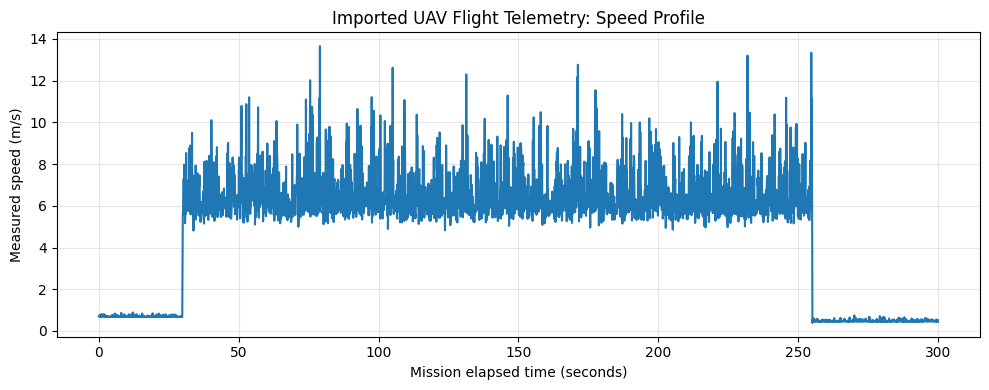

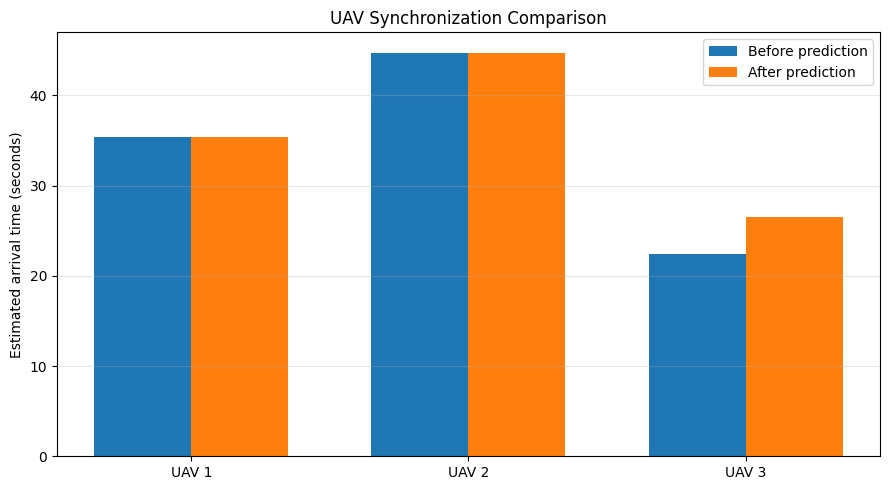


FINAL SUMMARY
Source: public GitHub UAV flight telemetry CSV
Valid telemetry rows: 3000
Training samples: 2400
Testing samples: 600
MAE: 0.0034
R2 score: 0.9999
Initial sync error: 22.361 s
Predicted sync error: 18.251 s
Context-aware action demonstration: WAIT

IMPORTANT LIMITATIONS:
1. Required speed is mathematically derived, not a dataset label.
2. Distance-to-go is estimated from speed and remaining time.
3. Network traffic, load, delay, and cost are illustrative.
4. The action scores are not a trained contextual bandit.
5. The synchronization demo is not real-flight validation.


In [ ]:

# ================================================================
# UAV NETWORK DIGITAL TWIN
# Public UAV dataset + Random Forest + Contextual Bandit demo
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from IPython.display import display

np.random.seed(42)

# ================================================================
# 1. DOWNLOAD PUBLIC UAV FLIGHT DATASET
# ================================================================

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "yogesh031020/drone-flight-operations-data/"
    "main/2024-05-20_Autonomous_Waypoint_Mission.csv"
)

print("Downloading public UAV flight telemetry dataset...")

df = pd.read_csv(DATA_URL)

print("\nDataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())

# ================================================================
# 2. PREPARE FLIGHT TELEMETRY
# ================================================================

# Normalize column names
df.columns = [
    str(c).strip().lower()
    for c in df.columns
]

# Required telemetry fields
if "speed_ms" not in df.columns:
    if all(c in df.columns for c in ["vx_ms", "vy_ms"]):
        df["speed_ms"] = np.sqrt(
            df["vx_ms"]**2 + df["vy_ms"]**2
        )
    else:
        raise ValueError(
            "Dataset has no recognizable speed column. "
            "Check the displayed column names."
        )

if "time_s" not in df.columns:
    raise ValueError(
        "Dataset must contain time_s for mission elapsed time."
    )

# Keep valid numeric measurements
df["time_s"] = pd.to_numeric(df["time_s"], errors="coerce")
df["speed_ms"] = pd.to_numeric(df["speed_ms"], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["time_s", "speed_ms"])
df = df.sort_values("time_s").reset_index(drop=True)

# Remove invalid or stationary speed values for this training task
df = df[df["speed_ms"] > 0].copy()

if len(df) < 30:
    raise ValueError(
        "Not enough valid telemetry rows to build a model."
    )

print("\nValid telemetry records:", len(df))
print("Observed speed range:",
      round(df["speed_ms"].min(), 3), "to",
      round(df["speed_ms"].max(), 3), "m/s")

# ================================================================
# 3. BUILD SYNCHRONIZATION TRAINING FEATURES
#
# Important:
# This public flight log does not directly provide the target
# variable "required synchronized speed".
# We derive a mathematical training target for this prototype.
# ================================================================

# Estimate remaining mission time from the recorded trajectory
mission_end_time = df["time_s"].max()

df["remaining_time"] = (
    mission_end_time - df["time_s"]
).clip(lower=1.0)

# Distance-to-go proxy from speed and remaining time.
# This is an estimate, not GPS-derived geometric distance.
df["distance_proxy"] = (
    df["speed_ms"] * df["remaining_time"]
)

df["arrival_time"] = (
    df["distance_proxy"] /
    df["speed_ms"].clip(lower=0.05)
)

# Common arrival time proxy
df["common_time"] = df["remaining_time"]

df["sync_error"] = np.abs(
    df["arrival_time"] - df["common_time"]
)

# Derived mathematical target: speed needed to cover
# the estimated distance in the remaining time.
df["required_speed"] = (
    df["distance_proxy"] /
    df["common_time"].clip(lower=1.0)
)

# Features and target
feature_columns = [
    "distance_proxy",
    "speed_ms",
    "arrival_time",
    "common_time",
    "sync_error"
]

X = df[feature_columns]
y = df["required_speed"]

# Clean the training data
valid = (
    np.isfinite(X).all(axis=1)
    & np.isfinite(y)
    & (y > 0)
)

X = X.loc[valid]
y = y.loc[valid]

if len(X) < 30:
    raise ValueError("Too few valid training samples after cleaning.")

print("\nTraining dataset shape:", X.shape)
print("Target variable: derived required_speed")
print("\nExample training rows:")
display(X.head())

# ================================================================
# 4. TRAIN RANDOM FOREST REGRESSION
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("\n" + "=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE: {mae:.4f}")
print(f"R2 score: {r2:.4f}")

# ================================================================
# 5. INITIALIZE THREE UAVS FOR THE SYNCHRONIZATION DEMO
# ================================================================

positions = np.array([
    [0.0, 0.0],
    [0.0, 10.0],
    [10.0, 0.0]
])

target = np.array([20.0, 20.0])

initial_speeds = np.array([0.8, 0.5, 1.0])

distances = np.linalg.norm(
    target - positions,
    axis=1
)

initial_times = distances / initial_speeds
common_time = np.max(initial_times)

initial_sync_error = (
    np.max(initial_times) - np.min(initial_times)
)

individual_errors = np.abs(
    initial_times - common_time
)

print("\nINITIAL UAV STATE")

for i in range(3):
    print(
        f"UAV {i+1}: distance={distances[i]:.2f} m, "
        f"speed={initial_speeds[i]:.3f} m/s, "
        f"arrival={initial_times[i]:.2f} s"
    )

print(f"Initial synchronization error: {initial_sync_error:.3f} s")

# ================================================================
# 6. PREDICT REQUIRED SPEEDS
# ================================================================

uav_inputs = pd.DataFrame({
    "distance_proxy": distances,
    "speed_ms": initial_speeds,
    "arrival_time": initial_times,
    "common_time": np.full(3, common_time),
    "sync_error": individual_errors
})

predicted_speeds = model.predict(
    uav_inputs[feature_columns]
)

# The current model is trained from real telemetry with a derived
# target. These predictions are experimental, not validated
# synchronization speeds for a real aircraft.

predicted_speeds = np.clip(
    predicted_speeds,
    max(0.05, y.min()),
    y.max()
)

predicted_times = distances / np.maximum(
    predicted_speeds, 0.05
)

final_sync_error = (
    np.max(predicted_times) - np.min(predicted_times)
)

print("\nML SYNCHRONIZATION DEMONSTRATION")

for i in range(3):
    print(
        f"UAV {i+1}: initial speed={initial_speeds[i]:.3f} m/s, "
        f"predicted speed={predicted_speeds[i]:.3f} m/s, "
        f"estimated arrival={predicted_times[i]:.2f} s"
    )

print(f"\nInitial sync error: {initial_sync_error:.3f} s")
print(f"Predicted sync error: {final_sync_error:.3f} s")

# ================================================================
# 7. SIMULATED NETWORK CONTEXT
# These are illustrative values, not columns from the flight log.
# ================================================================

traffic = 0.70
network_load = 0.65
communication_delay = 0.60
operational_cost = 0.45

print("\nSIMULATED NETWORK CONTEXT")
print("Traffic:", traffic)
print("Network load:", network_load)
print("Communication delay:", communication_delay)
print("Operational cost:", operational_cost)

# ================================================================
# 8. SIMPLE CONTEXTUAL ACTION DEMONSTRATION
#
# This is a transparent score-based prototype, not a trained
# contextual bandit. Real bandit learning needs feedback/rewards.
# ================================================================

action_scores = {
    "MOVE": (
        1.0
        - 0.35 * traffic
        - 0.25 * network_load
        - 0.20 * communication_delay
        - 0.20 * operational_cost
    ),
    "WAIT": (
        0.20
        + 0.35 * traffic
        + 0.30 * network_load
        + 0.15 * communication_delay
        - 0.15 * operational_cost
    ),
    "RETRAIN": 0.10
}

selected_action = max(
    action_scores,
    key=action_scores.get
)

print("\nCONTEXT-AWARE ACTION DEMONSTRATION")

for action, score in action_scores.items():
    print(f"{action}: score={score:.3f}")

print("Selected action:", selected_action)

# ================================================================
# 9. SIMPLE DIGITAL TWIN STATE
# ================================================================

digital_twin = {
    "positions": positions.copy(),
    "target": target.copy(),
    "speeds": predicted_speeds.copy(),
    "traffic": traffic,
    "network_load": network_load,
    "communication_delay": communication_delay,
    "operational_cost": operational_cost,
    "sync_error": final_sync_error,
    "last_action": selected_action
}

print("\nDIGITAL TWIN STATE")
print("Positions:\n", digital_twin["positions"])
print("Target:", digital_twin["target"])
print("Predicted speeds:", digital_twin["speeds"])
print("Last action:", digital_twin["last_action"])
print("Synchronization error:", digital_twin["sync_error"])

# ================================================================
# 10. PLOT REAL TELEMETRY SPEED
# ================================================================

plt.figure(figsize=(10, 4))
plt.plot(df["time_s"], df["speed_ms"])
plt.xlabel("Mission elapsed time (seconds)")
plt.ylabel("Measured speed (m/s)")
plt.title("Imported UAV Flight Telemetry: Speed Profile")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# 11. PLOT ARRIVAL TIMES BEFORE AND AFTER PREDICTION
# ================================================================

x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    initial_times,
    width,
    label="Before prediction"
)

plt.bar(
    x + width / 2,
    predicted_times,
    width,
    label="After prediction"
)

plt.xticks(x, ["UAV 1", "UAV 2", "UAV 3"])
plt.ylabel("Estimated arrival time (seconds)")
plt.title("UAV Synchronization Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# 12. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

print("Source: public GitHub UAV flight telemetry CSV")
print("Valid telemetry rows:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE: {mae:.4f}")
print(f"R2 score: {r2:.4f}")
print(f"Initial sync error: {initial_sync_error:.3f} s")
print(f"Predicted sync error: {final_sync_error:.3f} s")
print("Context-aware action demonstration:", selected_action)

print("\nIMPORTANT LIMITATIONS:")
print("1. Required speed is mathematically derived, not a dataset label.")
print("2. Distance-to-go is estimated from speed and remaining time.")
print("3. Network traffic, load, delay, and cost are illustrative.")
print("4. The action scores are not a trained contextual bandit.")
print("5. The synchronization demo is not real-flight validation.")


UAV FLIGHT DATASET LOADED
Dataset shape: (3000, 17)

Column names:
['timestamp', 'time_s', 'lat', 'lon', 'altitude_m', 'vx_ms', 'vy_ms', 'vz_ms', 'speed_ms', 'roll_deg', 'pitch_deg', 'yaw_deg', 'battery_pct', 'motor1_pwm', 'motor2_pwm', 'motor3_pwm', 'motor4_pwm']

First 10 records:


,timestamp,time_s,lat,lon,altitude_m,vx_ms,vy_ms,vz_ms,speed_ms,roll_deg,pitch_deg,yaw_deg,battery_pct,motor1_pwm,motor2_pwm,motor3_pwm,motor4_pwm
0,2024-05-20 00:00:00.000000,0.000000,12.971574,77.594609,0.000000,0.0,0.241328,0.668673,0.710889,0.327674,-1.300973,359.922234,100.064119,1181.820391,1206.699858,1207.130945,1195.725944
1,2024-05-20 00:00:00.100033,0.100033,12.971566,77.594604,0.066890,0.0,0.205896,0.668673,0.699655,0.699425,1.386350,359.966695,100.023186,1195.001839,1202.554365,1199.991333,1205.397323
2,2024-05-20 00:00:00.200067,0.200067,12.971562,77.594602,0.133779,0.0,-0.233733,0.668673,0.708347,4.075703,-1.917346,359.999173,99.914637,1221.034031,1194.520794,1193.037964,1188.756435
3,2024-05-20 00:00:00.300100,0.300100,12.971552,77.594623,0.200669,0.0,0.090261,0.668673,0.674738,0.509005,2.656949,359.934879,99.959872,1205.403442,1216.811070,1204.152895,1195.374076
4,2024-05-20 00:00:00.400133,0.400133,12.971550,77.594629,0.267559,0.0,0.391630,0.668673,0.774918,-1.478401,-2.124835,0.018938,99.761274,1205.438693,1207.412960,1216.148015,1215.602501
5,2024-05-20 00:00:00.500167,0.500167,12.971530,77.594646,0.334448,0.0,0.104085,0.668673,0.676726,2.555104,2.473927,359.909522,99.803372,1216.003818,1201.056634,1206.052628,1208.830878
6,2024-05-20 00:00:00.600200,0.600200,12.971527,77.594637,0.401338,0.0,-0.106585,0.668673,0.677115,0.232630,-4.738838,359.805482,99.921117,1206.364304,1210.125269,1212.514596,1197.693857
7,2024-05-20 00:00:00.700233,0.700233,12.971532,77.594644,0.468227,0.0,0.288840,0.668673,0.728390,0.262968,2.090395,359.767231,99.791313,1195.619360,1207.399326,1192.721863,1196.091401
8,2024-05-20 00:00:00.800267,0.800267,12.971527,77.594652,0.535117,0.0,-0.113965,0.668673,0.678316,6.171165,1.753480,359.523144,99.754708,1197.764083,1201.155943,1186.975841,1202.679598
9,2024-05-20 00:00:00.900300,0.900300,12.971530,77.594655,0.602007,0.0,-0.451535,0.668673,0.806851,-1.544745,0.204795,359.238812,99.663240,1203.083868,1212.291196,1200.793438,1200.245452



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   timestamp    3000 non-null   object 
 1   time_s       3000 non-null   float64
 2   lat          3000 non-null   float64
 3   lon          3000 non-null   float64
 4   altitude_m   3000 non-null   float64
 5   vx_ms        3000 non-null   float64
 6   vy_ms        3000 non-null   float64
 7   vz_ms        3000 non-null   float64
 8   speed_ms     3000 non-null   float64
 9   roll_deg     3000 non-null   float64
 10  pitch_deg    3000 non-null   float64
 11  yaw_deg      3000 non-null   float64
 12  battery_pct  3000 non-null   float64
 13  motor1_pwm   3000 non-null   float64
 14  motor2_pwm   3000 non-null   float64
 15  motor3_pwm   3000 non-null   float64
 16  motor4_pwm   3000 non-null   float64
dtypes: float64(16), object(1)
memory usage: 398.6+ KB

Statistical summa

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,3000,3000,2024-05-20 00:05:00.000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_s,3000.0,NaN,NaN,NaN,150.0,86.645855,0.0,75.0,150.0,225.0,300.0
lat,3000.0,NaN,NaN,NaN,12.971567,0.00031,12.97118,12.971323,12.97143,12.971787,12.972311
lon,3000.0,NaN,NaN,NaN,77.594594,0.0002,77.594168,77.594455,77.594559,77.594727,77.595058
altitude_m,3000.0,NaN,NaN,NaN,17.50696,5.231039,0.0,18.955545,19.784655,20.231581,21.809101
vx_ms,3000.0,NaN,NaN,NaN,4.202607,2.44046,0.0,3.478717,5.468037,5.734062,6.603673
vy_ms,3000.0,NaN,NaN,NaN,-0.001959,0.198219,-0.674772,-0.127149,0.002478,0.125012,0.639404
vz_ms,3000.0,NaN,NaN,NaN,0.000037,3.116416,-11.394681,-1.613935,-0.22885,1.521029,12.628894
speed_ms,3000.0,NaN,NaN,NaN,5.059216,2.787612,0.386501,4.521002,5.891927,6.617831,13.654547
roll_deg,3000.0,NaN,NaN,NaN,0.046004,2.020491,-6.851373,-1.283655,0.032556,1.405669,6.87982



Missing values:


,Missing Values
timestamp,0
time_s,0
lat,0
lon,0
altitude_m,0
vx_ms,0
vy_ms,0
vz_ms,0
speed_ms,0
roll_deg,0


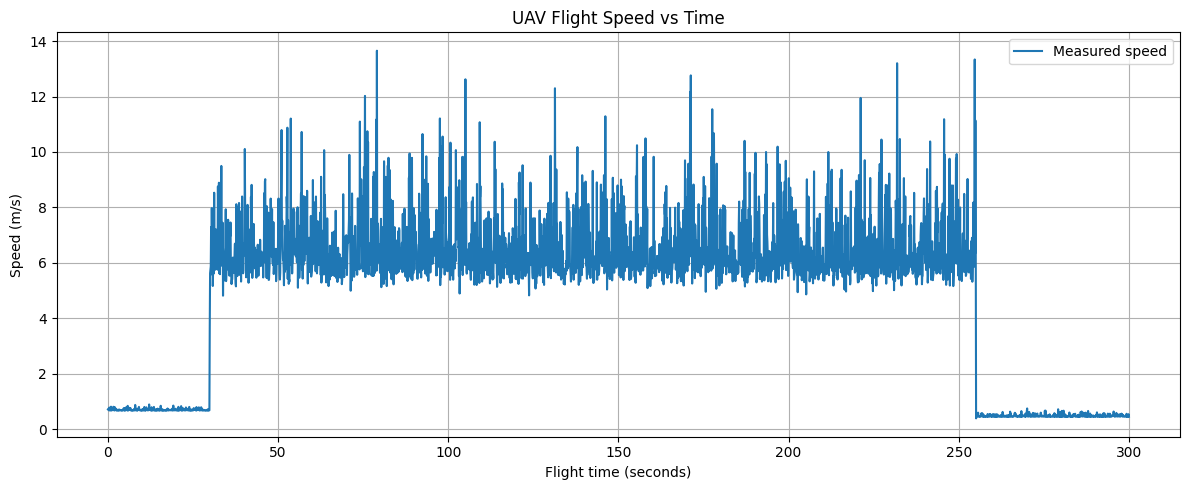

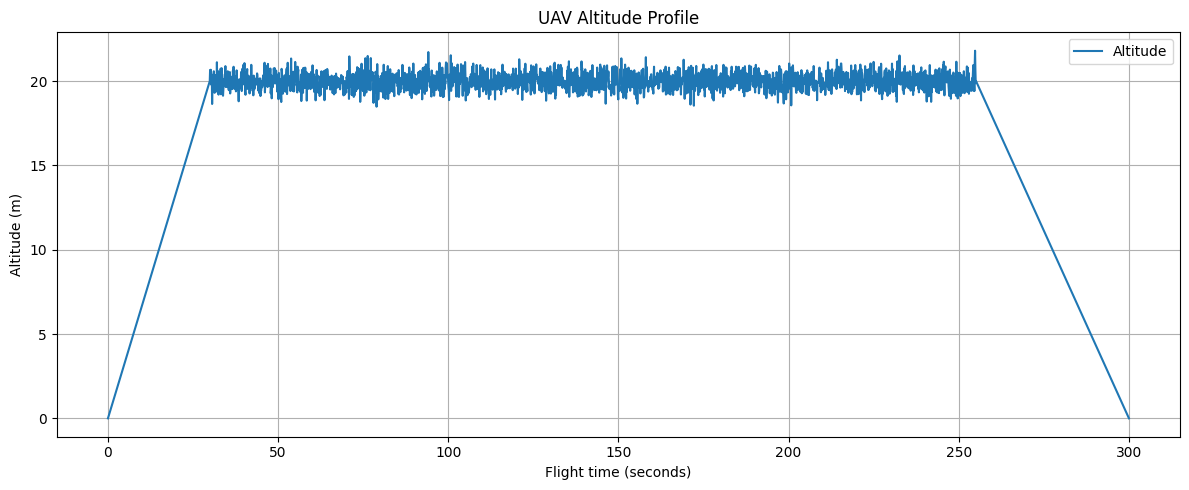

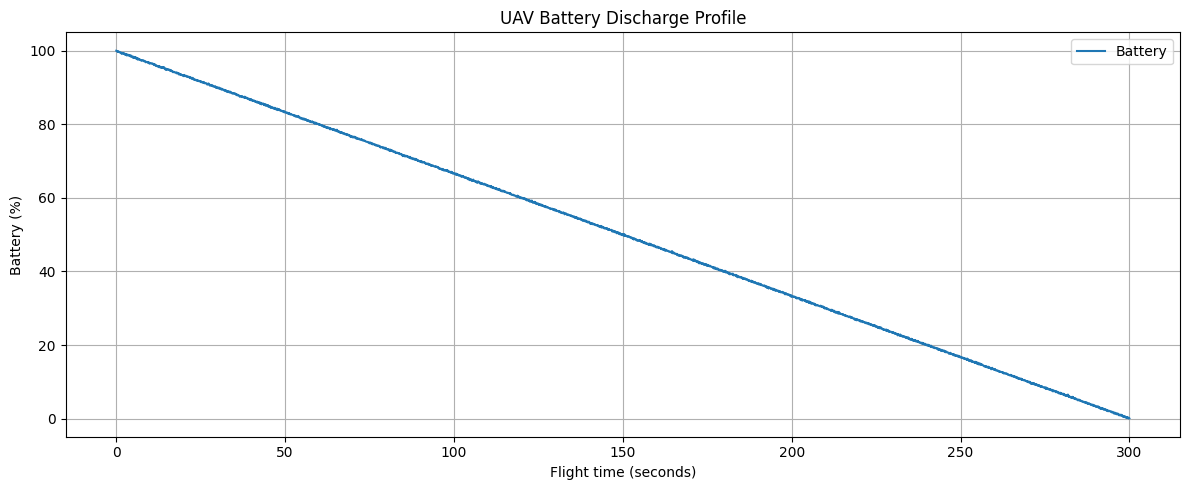

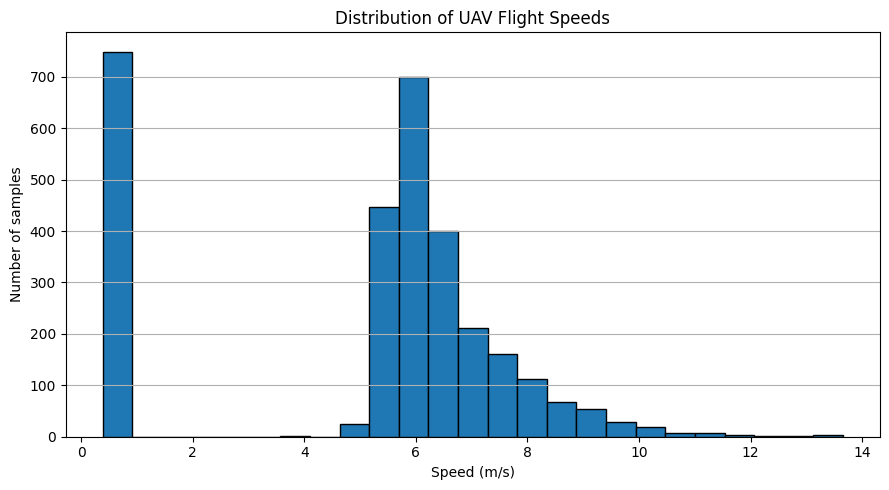

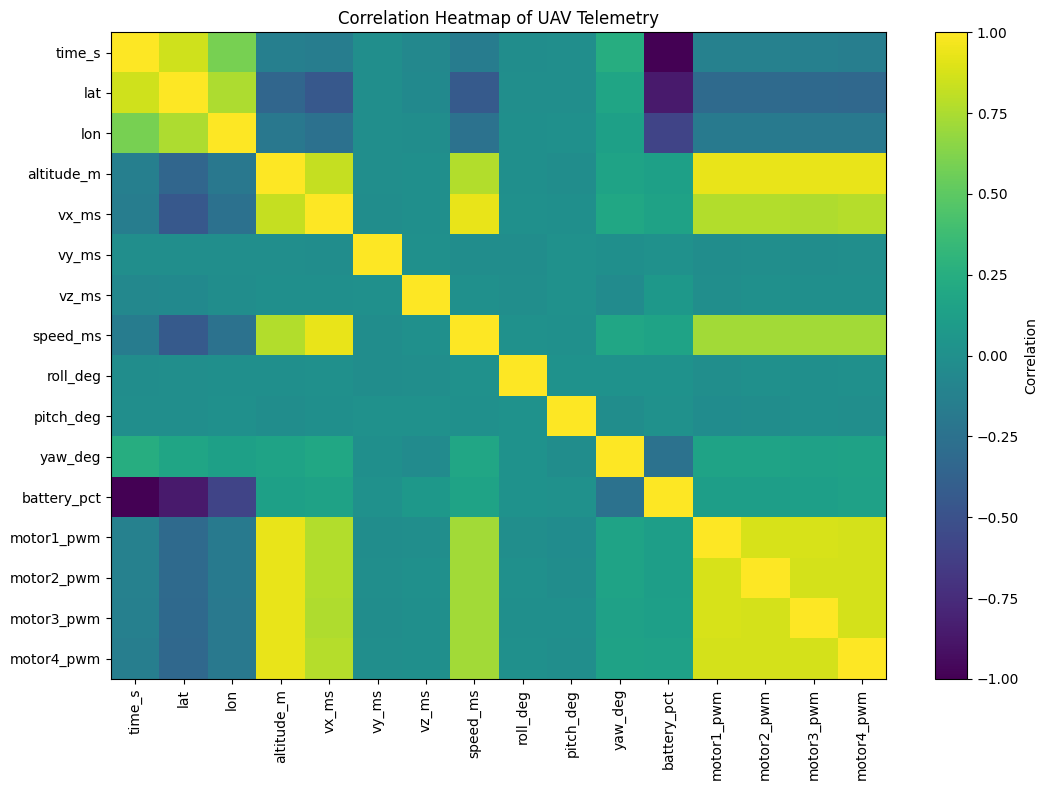


RANDOM FOREST MODEL EVALUATION
Input features: ['speed_ms', 'altitude_m', 'battery_pct', 'vx_ms', 'vy_ms', 'vz_ms', 'roll_deg', 'pitch_deg', 'yaw_deg']
Training samples: 2399
Testing samples: 600
MAE  : 2.3049 m/s
RMSE : 2.4837 m/s
R²   : 0.1875

Prediction results:


,Time (s),Actual next speed (m/s),Predicted next speed (m/s),Absolute error (m/s)
0,239.979993,6.001361,6.113204,0.111843
1,240.080027,6.218554,6.966364,0.747810
2,240.180060,7.156022,6.774521,0.381501
3,240.280093,5.740785,6.092010,0.351225
4,240.380127,7.688696,6.595713,1.092983
5,240.480160,6.662287,6.485689,0.176598
6,240.580193,9.384120,9.488516,0.104396
7,240.680227,5.752935,6.426481,0.673546
8,240.780260,5.284248,6.162132,0.877883
9,240.880293,5.556423,6.144808,0.588385


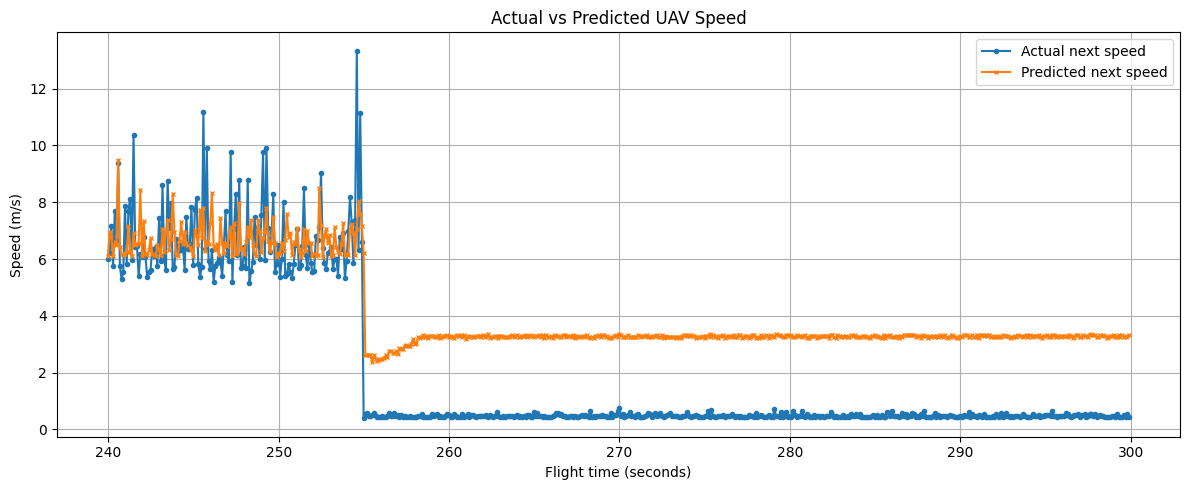

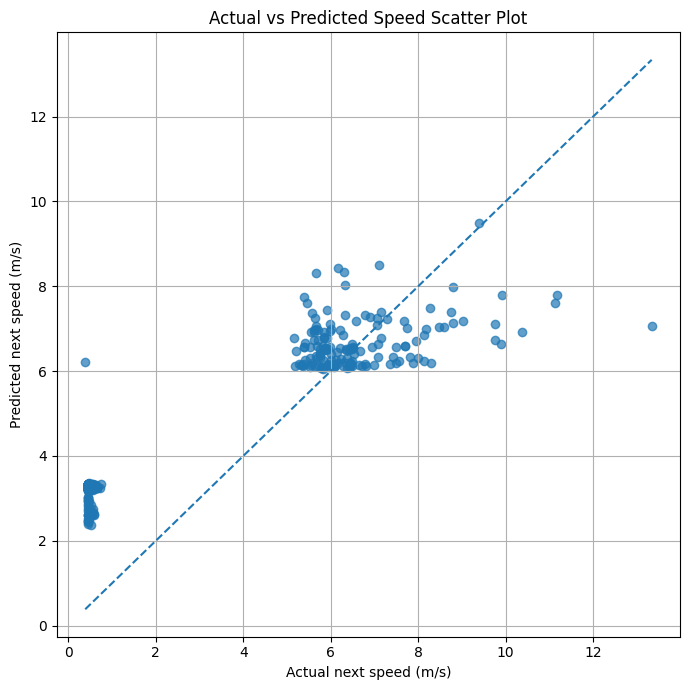

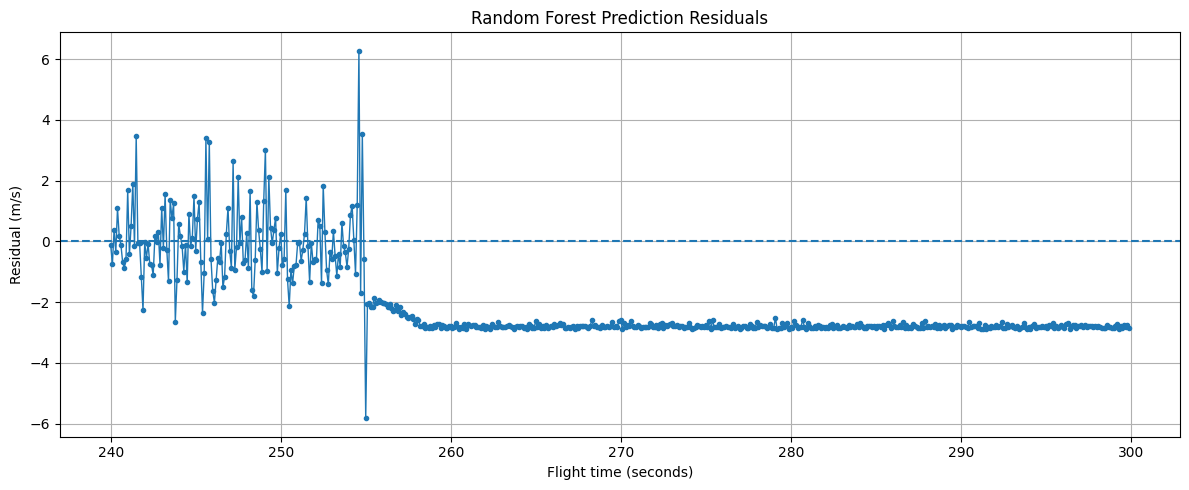

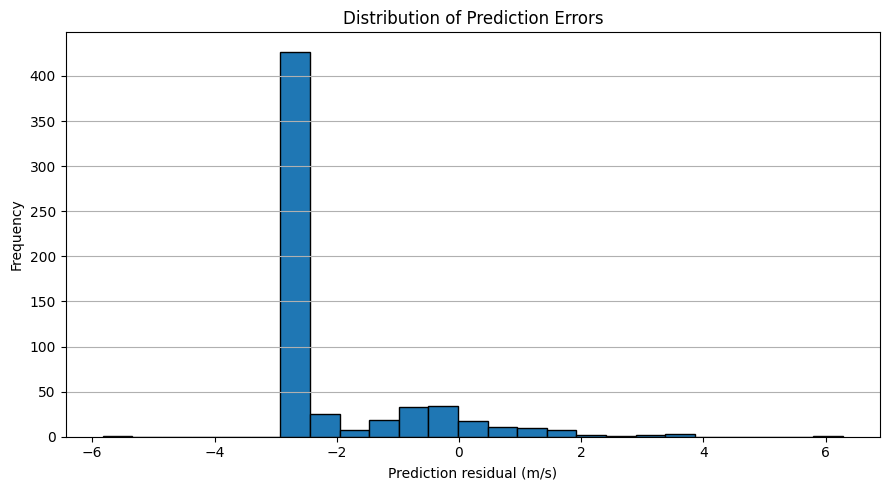

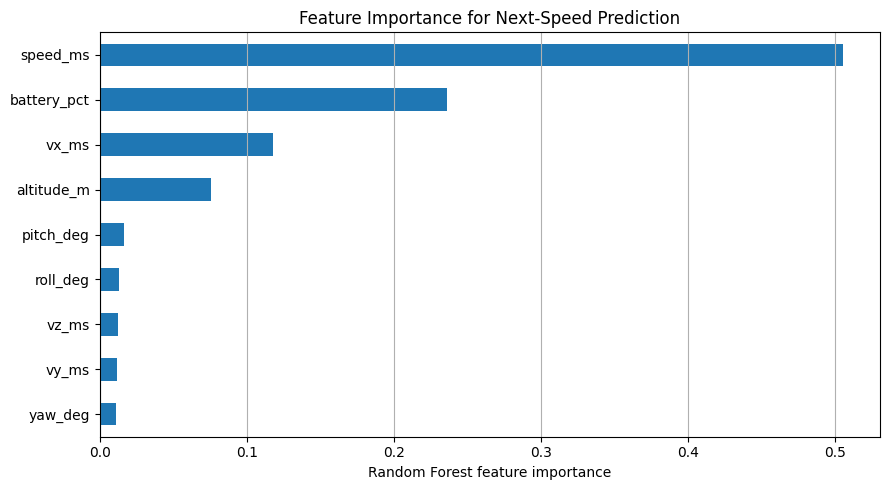


Feature importance:


,Importance
speed_ms,0.505041
battery_pct,0.235903
vx_ms,0.117916
altitude_m,0.075909
pitch_deg,0.016822
roll_deg,0.013305
vz_ms,0.012344
vy_ms,0.011966
yaw_deg,0.010795



SIMULATED UAV SYNCHRONIZATION RESULTS


,UAV,Distance (m),Initial speed (m/s),Initial arrival time (s),Simulated adjusted speed (m/s),Adjusted arrival time (s)
0,UAV 1,28.284,0.8,35.355,0.632,44.721
1,UAV 2,22.361,0.5,44.721,0.500,44.721
2,UAV 3,22.361,1.0,22.361,0.500,44.721


Initial arrival-time spread: 22.361 seconds
Adjusted arrival-time spread: 0.000 seconds


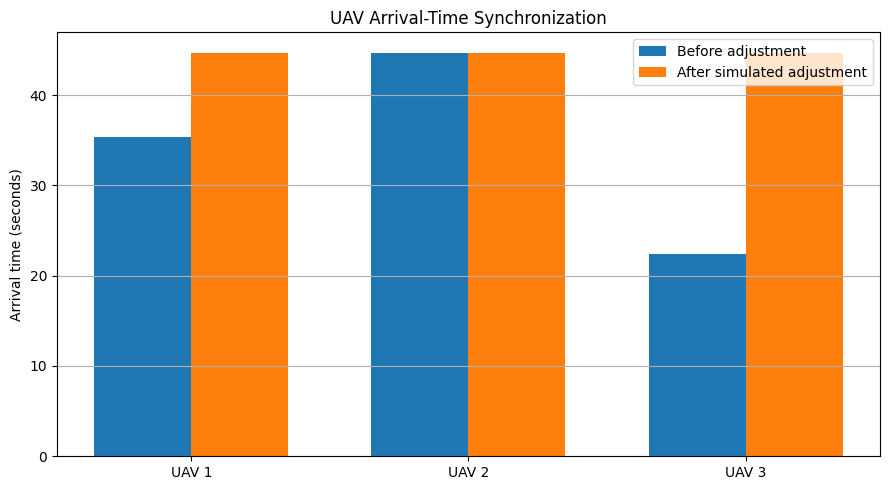

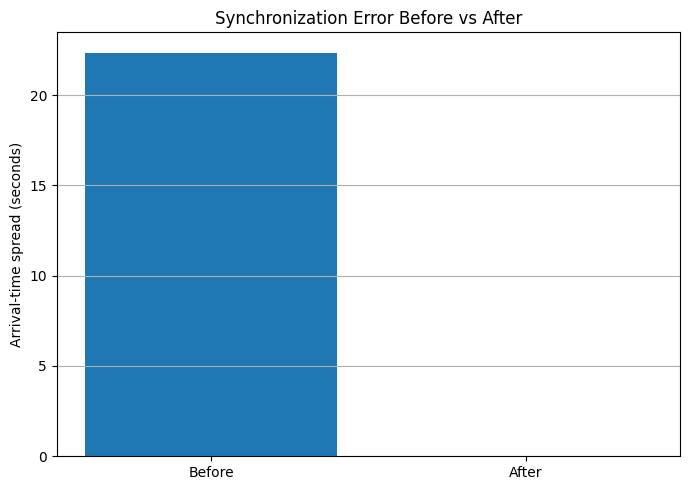

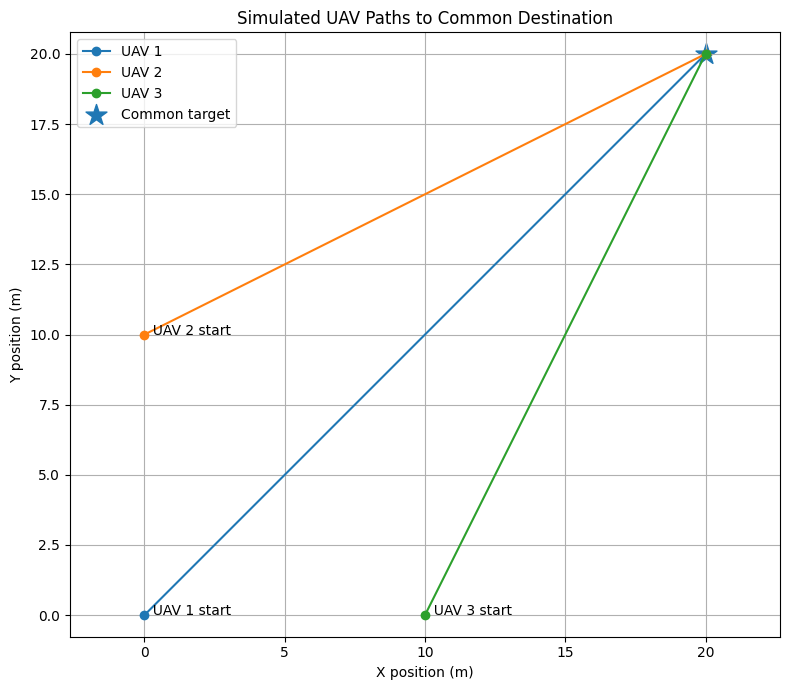


Simulated network context:


,Context variable,Illustrative value (0 to 1)
0,traffic,0.70
1,network_load,0.65
2,communication_delay,0.60
3,operational_cost,0.45


Illustrative action scores:


,Action,Score
1,WAIT,0.6625
0,MOVE,0.3825
2,RETRAIN,0.1000


Selected illustrative action: WAIT


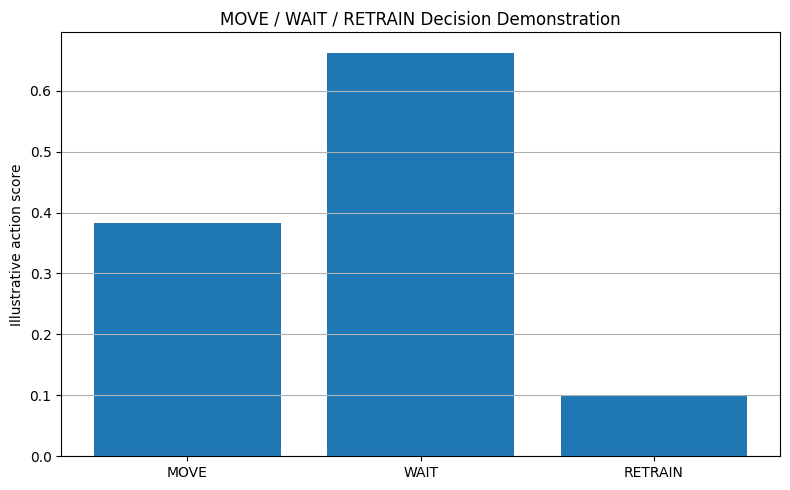

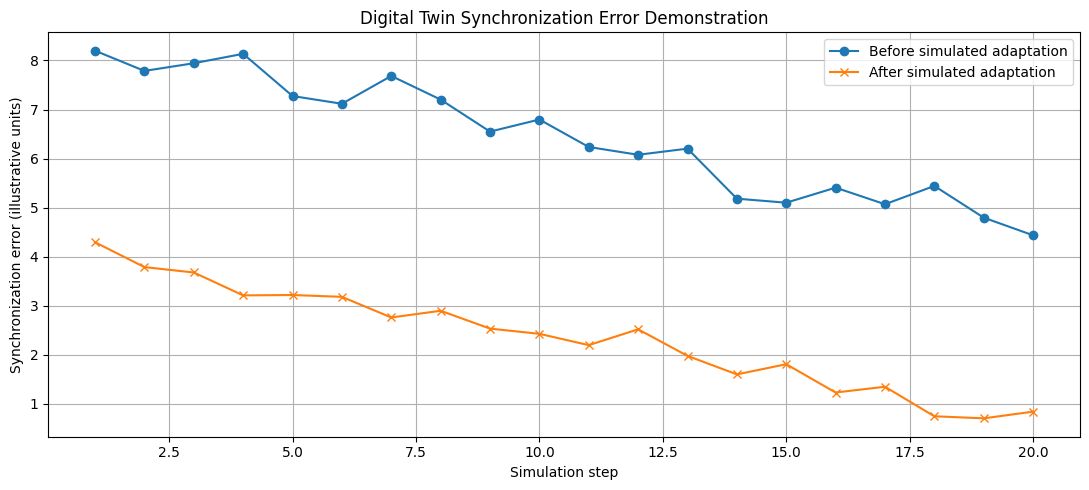


Adaptive retraining demonstration
90th-percentile validation error threshold: 2.8592 m/s
Mean absolute prediction error: 2.3049 m/s
Retraining trigger: NOT triggered by this simple check

Note: This is only a demonstration trigger. It does not prove concept drift, and the model is not automatically retrained here.

FINAL PROJECT OUTPUT SUMMARY


,Metric,Result
0,Dataset rows after cleaning,3000
1,Training samples,2399
2,Testing samples,600
3,MAE (m/s),2.3049
4,RMSE (m/s),2.4837
5,R-squared,0.1875
6,Initial synchronization spread (s),22.3607
7,Adjusted synchronization spread (s),0.0
8,Illustrative selected action,WAIT


All available plots and evaluation outputs generated.


In [ ]:

# ============================================================
# UAV DIGITAL TWIN PROJECT
# Dataset + Random Forest + Extra Graphs + Simulated Synchronization
# Run this complete code in ONE Google Colab cell
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

np.random.seed(42)

# ------------------------------------------------------------
# 1. DOWNLOAD DATASET DIRECTLY FROM GITHUB
# ------------------------------------------------------------

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "yogesh031020/drone-flight-operations-data/"
    "main/2024-05-20_Autonomous_Waypoint_Mission.csv"
)

df = pd.read_csv(DATA_URL)
df.columns = df.columns.str.strip().str.lower()

print("=" * 65)
print("UAV FLIGHT DATASET LOADED")
print("=" * 65)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 10 records:")
display(df.head(10))

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

# ------------------------------------------------------------
# 2. CHECK AND PREPARE REQUIRED COLUMNS
# ------------------------------------------------------------

if "time_s" not in df.columns:
    raise ValueError(
        "The CSV does not contain time_s. "
        "Check the downloaded file's column names."
    )

if "speed_ms" not in df.columns:
    if {"vx_ms", "vy_ms"}.issubset(df.columns):
        vz = df["vz_ms"] if "vz_ms" in df.columns else 0
        df["speed_ms"] = np.sqrt(
            df["vx_ms"]**2 + df["vy_ms"]**2 + np.asarray(vz)**2
        )
    else:
        raise ValueError(
            "Could not find speed_ms or the velocity components."
        )

# Convert key columns to numeric
for col in ["time_s", "speed_ms"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort data chronologically
df = df.dropna(subset=["time_s", "speed_ms"])
df = df.sort_values("time_s").reset_index(drop=True)

# Remove duplicate timestamps for next-sample prediction
df = df.drop_duplicates(subset="time_s", keep="last")
df = df.reset_index(drop=True)

# ------------------------------------------------------------
# 3. GRAPH: FLIGHT SPEED OVER TIME
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))
plt.plot(df["time_s"], df["speed_ms"], label="Measured speed")
plt.xlabel("Flight time (seconds)")
plt.ylabel("Speed (m/s)")
plt.title("UAV Flight Speed vs Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. GRAPH: ALTITUDE OVER TIME, IF AVAILABLE
# ------------------------------------------------------------

if "altitude_m" in df.columns:
    plt.figure(figsize=(12, 5))
    plt.plot(df["time_s"], df["altitude_m"], label="Altitude")
    plt.xlabel("Flight time (seconds)")
    plt.ylabel("Altitude (m)")
    plt.title("UAV Altitude Profile")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. GRAPH: BATTERY OVER TIME, IF AVAILABLE
# ------------------------------------------------------------

if "battery_pct" in df.columns:
    plt.figure(figsize=(12, 5))
    plt.plot(df["time_s"], df["battery_pct"], label="Battery")
    plt.xlabel("Flight time (seconds)")
    plt.ylabel("Battery (%)")
    plt.title("UAV Battery Discharge Profile")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. GRAPH: SPEED DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.hist(df["speed_ms"].dropna(), bins=25, edgecolor="black")
plt.xlabel("Speed (m/s)")
plt.ylabel("Number of samples")
plt.title("Distribution of UAV Flight Speeds")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. GRAPH: CORRELATION BETWEEN NUMERIC VARIABLES
# ------------------------------------------------------------

numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(11, 8))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(corr.columns)), corr.columns,
    rotation=90
)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap of UAV Telemetry")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. PREPARE MACHINE-LEARNING DATA
# Predict NEXT-SAMPLE speed using current telemetry.
# This is a one-step-ahead forecasting demonstration.
# ------------------------------------------------------------

candidate_features = [
    "speed_ms",
    "altitude_m",
    "battery_pct",
    "vx_ms",
    "vy_ms",
    "vz_ms",
    "roll_deg",
    "pitch_deg",
    "yaw_deg"
]

features = [
    c for c in candidate_features
    if c in df.columns and df[c].notna().sum() > 0
]

if "speed_ms" not in features:
    raise ValueError("speed_ms is required as an input feature.")

# The target is the speed at the NEXT recorded timestamp.
df["next_speed_ms"] = df["speed_ms"].shift(-1)

model_df = df[features + ["next_speed_ms", "time_s"]].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna().reset_index(drop=True)

if len(model_df) < 20:
    raise ValueError(
        "Not enough usable records for a meaningful train/test split."
    )

X = model_df[features]
y = model_df["next_speed_ms"]

# Chronological split avoids randomly mixing future and past samples.
split = int(len(model_df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
test_times = model_df["time_s"].iloc[split:]

model = RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ------------------------------------------------------------
# 9. PRINT MACHINE-LEARNING EVALUATION METRICS
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 65)
print("RANDOM FOREST MODEL EVALUATION")
print("=" * 65)
print("Input features:", features)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"MAE  : {mae:.4f} m/s")
print(f"RMSE : {rmse:.4f} m/s")
print(f"R²   : {r2:.4f}")

if r2 < 0:
    print("Note: R² below zero means this model performed worse than")
    print("predicting the test-set mean on this test split.")

results = pd.DataFrame({
    "Time (s)": test_times.to_numpy(),
    "Actual next speed (m/s)": y_test.to_numpy(),
    "Predicted next speed (m/s)": y_pred,
    "Absolute error (m/s)": np.abs(y_test.to_numpy() - y_pred)
})

print("\nPrediction results:")
display(results.head(15))

# ------------------------------------------------------------
# 10. GRAPH: ACTUAL VS PREDICTED SPEED
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))
plt.plot(
    test_times, y_test,
    label="Actual next speed", marker="o", markersize=3
)
plt.plot(
    test_times, y_pred,
    label="Predicted next speed", marker="x", markersize=3
)
plt.xlabel("Flight time (seconds)")
plt.ylabel("Speed (m/s)")
plt.title("Actual vs Predicted UAV Speed")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. GRAPH: PREDICTION SCATTER PLOT
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.7)

low = min(y_test.min(), np.min(y_pred))
high = max(y_test.max(), np.max(y_pred))
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual next speed (m/s)")
plt.ylabel("Predicted next speed (m/s)")
plt.title("Actual vs Predicted Speed Scatter Plot")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. GRAPH: RESIDUAL ERROR
# Residual = actual - predicted
# ------------------------------------------------------------

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(12, 5))
plt.plot(test_times, residuals, marker=".", linewidth=1)
plt.axhline(0, linestyle="--")
plt.xlabel("Flight time (seconds)")
plt.ylabel("Residual (m/s)")
plt.title("Random Forest Prediction Residuals")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. GRAPH: ERROR DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=25, edgecolor="black")
plt.xlabel("Prediction residual (m/s)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. GRAPH: FEATURE IMPORTANCE
# ------------------------------------------------------------

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

plt.figure(figsize=(9, 5))
importance.plot(kind="barh")
plt.xlabel("Random Forest feature importance")
plt.title("Feature Importance for Next-Speed Prediction")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

print("\nFeature importance:")
display(importance.sort_values(ascending=False).to_frame("Importance"))

# ------------------------------------------------------------
# 15. SIMULATED THREE-UAV SYNCHRONIZATION
# This section is a mathematical simulation, not flight control.
# ------------------------------------------------------------

positions = np.array([
    [0.0, 0.0],
    [0.0, 10.0],
    [10.0, 0.0]
])

target = np.array([20.0, 20.0])

initial_speeds = np.array([0.8, 0.5, 1.0])
distances = np.linalg.norm(positions - target, axis=1)

initial_times = distances / initial_speeds
common_time = np.max(initial_times)

# Simple baseline: each UAV adjusts its speed to target the
# slowest initial arrival time.
adjusted_speeds = distances / common_time
adjusted_times = distances / adjusted_speeds

initial_error = np.ptp(initial_times)
adjusted_error = np.ptp(adjusted_times)

sync_results = pd.DataFrame({
    "UAV": ["UAV 1", "UAV 2", "UAV 3"],
    "Distance (m)": distances,
    "Initial speed (m/s)": initial_speeds,
    "Initial arrival time (s)": initial_times,
    "Simulated adjusted speed (m/s)": adjusted_speeds,
    "Adjusted arrival time (s)": adjusted_times
})

print("\n" + "=" * 65)
print("SIMULATED UAV SYNCHRONIZATION RESULTS")
print("=" * 65)
display(sync_results.round(3))
print(f"Initial arrival-time spread: {initial_error:.3f} seconds")
print(f"Adjusted arrival-time spread: {adjusted_error:.3f} seconds")

# ------------------------------------------------------------
# 16. GRAPH: ARRIVAL TIMES BEFORE AND AFTER ADJUSTMENT
# ------------------------------------------------------------

x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    x - width / 2, initial_times, width,
    label="Before adjustment"
)
plt.bar(
    x + width / 2, adjusted_times, width,
    label="After simulated adjustment"
)
plt.xticks(x, ["UAV 1", "UAV 2", "UAV 3"])
plt.ylabel("Arrival time (seconds)")
plt.title("UAV Arrival-Time Synchronization")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. GRAPH: SYNCHRONIZATION ERROR COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))
plt.bar(
    ["Before", "After"],
    [initial_error, adjusted_error]
)
plt.ylabel("Arrival-time spread (seconds)")
plt.title("Synchronization Error Before vs After")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 18. GRAPH: SIMULATED UAV TRAJECTORIES
# Straight-line paths to a common target.
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

for i, start in enumerate(positions):
    plt.plot(
        [start[0], target[0]],
        [start[1], target[1]],
        marker="o",
        label=f"UAV {i+1}"
    )
    plt.text(start[0], start[1], f"  UAV {i+1} start")

plt.scatter(
    target[0], target[1],
    marker="*", s=250, label="Common target"
)
plt.xlabel("X position (m)")
plt.ylabel("Y position (m)")
plt.title("Simulated UAV Paths to Common Destination")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 19. SIMULATED CONTEXTUAL ACTION SCORES
# These scores are illustrative rules, NOT a trained bandit.
# ------------------------------------------------------------

context = {
    "traffic": 0.70,
    "network_load": 0.65,
    "communication_delay": 0.60,
    "operational_cost": 0.45
}

action_scores = {
    "MOVE": (
        1
        - 0.35 * context["traffic"]
        - 0.25 * context["network_load"]
        - 0.20 * context["communication_delay"]
        - 0.20 * context["operational_cost"]
    ),
    "WAIT": (
        0.20
        + 0.35 * context["traffic"]
        + 0.30 * context["network_load"]
        + 0.15 * context["communication_delay"]
        - 0.15 * context["operational_cost"]
    ),
    "RETRAIN": 0.10
}

selected_action = max(action_scores, key=action_scores.get)

print("\nSimulated network context:")
display(pd.DataFrame(
    list(context.items()),
    columns=["Context variable", "Illustrative value (0 to 1)"]
))

print("Illustrative action scores:")
display(pd.DataFrame(
    list(action_scores.items()),
    columns=["Action", "Score"]
).sort_values("Score", ascending=False))

print("Selected illustrative action:", selected_action)

# ------------------------------------------------------------
# 20. GRAPH: ACTION SCORES
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.bar(
    list(action_scores.keys()),
    list(action_scores.values())
)
plt.ylabel("Illustrative action score")
plt.title("MOVE / WAIT / RETRAIN Decision Demonstration")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 21. SIMULATED DIGITAL TWIN ERROR HISTORY
# This is generated demonstration data, not measured telemetry.
# ------------------------------------------------------------

steps = np.arange(1, 21)

error_before = np.linspace(8, 5, 20) + np.random.normal(0, 0.4, 20)
error_before = np.maximum(error_before, 0)

error_after = np.linspace(4, 0.8, 20) + np.random.normal(0, 0.2, 20)
error_after = np.maximum(error_after, 0)

plt.figure(figsize=(11, 5))
plt.plot(steps, error_before, marker="o", label="Before simulated adaptation")
plt.plot(steps, error_after, marker="x", label="After simulated adaptation")
plt.xlabel("Simulation step")
plt.ylabel("Synchronization error (illustrative units)")
plt.title("Digital Twin Synchronization Error Demonstration")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 22. SIMULATED ADAPTIVE RETRAINING DEMONSTRATION
# ------------------------------------------------------------

errors = np.abs(residuals)
threshold = np.quantile(errors, 0.90)

print("\nAdaptive retraining demonstration")
print(f"90th-percentile validation error threshold: {threshold:.4f} m/s")
print(f"Mean absolute prediction error: {np.mean(errors):.4f} m/s")

if np.mean(errors) > threshold:
    print("Retraining trigger: CHECK")
else:
    print("Retraining trigger: NOT triggered by this simple check")

print(
    "\nNote: This is only a demonstration trigger. "
    "It does not prove concept drift, and the model is not "
    "automatically retrained here."
)

# ------------------------------------------------------------
# 23. FINAL SUMMARY TABLE
# ------------------------------------------------------------

summary = pd.DataFrame({
    "Metric": [
        "Dataset rows after cleaning",
        "Training samples",
        "Testing samples",
        "MAE (m/s)",
        "RMSE (m/s)",
        "R-squared",
        "Initial synchronization spread (s)",
        "Adjusted synchronization spread (s)",
        "Illustrative selected action"
    ],
    "Result": [
        len(df),
        len(X_train),
        len(X_test),
        round(mae, 4),
        round(rmse, 4),
        round(r2, 4),
        round(initial_error, 4),
        round(adjusted_error, 4),
        selected_action
    ]
})

print("\n" + "=" * 65)
print("FINAL PROJECT OUTPUT SUMMARY")
print("=" * 65)
display(summary)
print("All available plots and evaluation outputs generated.")
